# Part 2: Detecting fake Instagram accounts with machine learning

**Question:** can we tell fake Instagram accounts from genuine ones using only what a profile shows publicly: posts, followers, following, bio, profile picture and username?

**Data:** the InstaFake dataset, released with the paper *Instagram Fake and Automated Account Detection* (F. C. Akyon and M. E. Kalfaoglu, 2019). It has 1,194 accounts collected in 2018 and labelled by hand as fake or genuine. Usernames were not released, only numbers. License: CC BY-NC 4.0.

**Plan:** check the data → compare fake and genuine accounts → build features → compare four models with cross-validation → test the best one once on accounts it has never seen → explain what it learned and where it fails.

In [1]:
%matplotlib inline
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, RepeatedStratifiedKFold, cross_validate, cross_val_predict
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42   # fixed, so every run gives the same numbers
print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

# Same chart style as Part 1
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#b5b3ad"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": MUTED, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
})

pandas 2.2.3 | scikit-learn 1.6.1


## Step 1: Load the data
The dataset comes as two files: one with fake accounts and one with genuine accounts. I join them and give the columns short names.

In [2]:
def load(path):
    with open(path, encoding="utf-8") as f:
        return pd.DataFrame(json.load(f))

accounts = pd.concat([load("data/instafake/fakeAccountData.json"),
                      load("data/instafake/realAccountData.json")], ignore_index=True)
accounts = accounts.rename(columns={
    "userMediaCount": "posts", "userFollowerCount": "followers", "userFollowingCount": "following",
    "userBiographyLength": "bio_length", "userHasProfilPic": "has_profile_pic", "userIsPrivate": "is_private",
    "usernameDigitCount": "username_digits", "usernameLength": "username_length", "isFake": "is_fake",
})
accounts = accounts[["posts", "followers", "following", "bio_length", "has_profile_pic",
                     "is_private", "username_digits", "username_length", "is_fake"]]
print("Accounts:", len(accounts))
accounts.head()

Accounts: 1194


,posts,followers,following,bio_length,has_profile_pic,is_private,username_digits,username_length,is_fake
0,0,25,1937,0,1,1,0,10,1
1,0,324,4122,0,1,0,4,15,1
2,0,15,399,0,0,0,3,12,1
3,1,14,107,0,1,0,1,10,1
4,0,264,4651,0,1,0,0,14,1


## Step 2: Check the data

In [3]:
print("Missing values:", int(accounts.isna().sum().sum()))
repeated = accounts.duplicated(keep="first")
print("Repeated rows:", int(repeated.sum()), "| all genuine accounts:", bool((accounts.loc[repeated, "is_fake"] == 0).all()))

accounts = accounts.drop_duplicates().reset_index(drop=True)
n_fake = int(accounts["is_fake"].sum())
print(f"After removing repeats: {len(accounts)} accounts, {n_fake} fake ({n_fake / len(accounts):.1%}), {len(accounts) - n_fake} genuine")
print(f"Always answering 'genuine' would be right {1 - n_fake / len(accounts):.1%} of the time, and catch 0 fakes")

Missing values: 0
Repeated rows: 29 | all genuine accounts: True
After removing repeats: 1165 accounts, 200 fake (17.2%), 965 genuine
Always answering 'genuine' would be right 82.8% of the time, and catch 0 fakes


**Why remove repeated rows?** If the same account sits in both the training data and the test data, the test becomes partly a memory test and the score looks better than it really is.

**Why accuracy is the wrong yardstick here:** only about 1 account in 6 is fake. A "model" that always answers *genuine* is right about 83% of the time and catches zero fakes. So I measure how well the **fake** class is caught:

- **Precision:** of the accounts we flag as fake, how many really are fake?
- **Recall:** of all fake accounts, how many do we catch?
- **F1:** one number that balances precision and recall (it is low if either one is low).
- **ROC-AUC:** how well the model *ranks* accounts from most to least suspicious (0.5 = random, 1.0 = perfect).

## Step 3: How do fake accounts differ?

In [4]:
traits = pd.DataFrame({
    "No posts": accounts["posts"] == 0,
    "Empty bio": accounts["bio_length"] == 0,
    "No profile picture": accounts["has_profile_pic"] == 0,
    "Digits in username": accounts["username_digits"] > 0,
    "Follows more accounts than follow it": accounts["following"] > accounts["followers"],
    "Private account": accounts["is_private"] == 1,
})
trait_share = traits.groupby(accounts["is_fake"]).mean().T
trait_share.columns = ["Genuine", "Fake"]

medians = accounts.groupby("is_fake")[["posts", "followers", "following", "bio_length"]].median().T
medians.columns = ["Genuine", "Fake"]
print("Median values:")
print(medians)
print()
print("Share of accounts with each trait:")
print((trait_share * 100).round(1).astype(str) + "%")

Median values:
            Genuine    Fake
posts          29.0     0.0
followers     342.0    29.5
following     418.0  1446.5
bio_length     12.0     0.0

Share of accounts with each trait:
                                     Genuine   Fake
No posts                                4.4%  57.5%
Empty bio                              39.1%  73.5%
No profile picture                      1.3%  39.5%
Digits in username                     11.1%  55.0%
Follows more accounts than follow it   69.3%  95.0%
Private account                        72.4%  32.5%


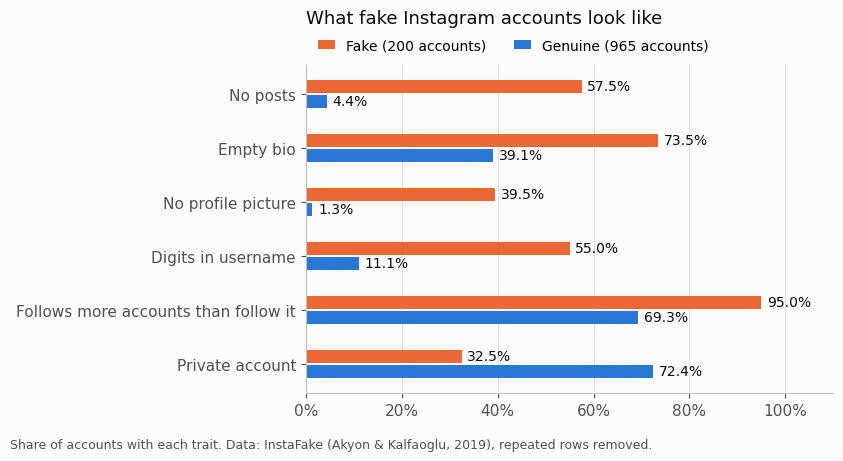

In [5]:
order = list(trait_share.index)
y = range(len(order))
fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.barh([i - 0.14 for i in y], trait_share["Fake"], height=0.24, color=ORANGE, label=f"Fake ({n_fake} accounts)")
ax.barh([i + 0.14 for i in y], trait_share["Genuine"], height=0.24, color=BLUE, label=f"Genuine ({len(accounts) - n_fake} accounts)")
for i, trait in enumerate(order):
    ax.text(trait_share.loc[trait, "Fake"] + 0.012, i - 0.14, f"{trait_share.loc[trait, 'Fake']:.1%}", va="center", color=INK, fontsize=10)
    ax.text(trait_share.loc[trait, "Genuine"] + 0.012, i + 0.14, f"{trait_share.loc[trait, 'Genuine']:.1%}", va="center", color=INK, fontsize=10)
ax.set_yticks(list(y))
ax.set_yticklabels(order)
ax.invert_yaxis()
ax.set_xlim(0, 1.1)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.grid(axis="y", visible=False)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, frameon=False, fontsize=10, handlelength=1.2)
ax.set_title("What fake Instagram accounts look like", loc="left", fontsize=13, pad=30)
fig.text(0.012, 0.01, "Share of accounts with each trait. Data: InstaFake (Akyon & Kalfaoglu, 2019), repeated rows removed.", color=MUTED, fontsize=9)
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig("images/fake_vs_genuine.png", dpi=150)
plt.show()

Fake accounts look empty and one-sided:

- Most have **no posts** (57.5% vs 4.4% of genuine accounts) and an **empty bio** (73.5% vs 39.1%).
- **39.5% have no profile picture** (genuine: 1.3%), and **55% have digits in the username** (genuine: 11.1%).
- They **follow far more accounts than follow them back.** The median fake account follows about 1,450 accounts and has about 30 followers. The median genuine account follows 418 and has 342.
- Genuine accounts are more often **private** (72.4% vs 32.5%).

No single trait separates the two groups. For example, 39% of genuine accounts also have an empty bio. That is why a model that combines the traits is needed.

## Step 4: Build features
Two extra columns, each easy to explain:

- **follower_following_ratio** = followers ÷ following. A fake account follows many people but few follow it back, so its ratio is tiny. (`clip(lower=1)` avoids dividing by zero for the few accounts that follow nobody.)
- **username_digit_share** = digits ÷ username length, so "ab12" (half digits) counts more than "abcdefgh12".

In [6]:
accounts["follower_following_ratio"] = accounts["followers"] / accounts["following"].clip(lower=1)
accounts["username_digit_share"] = accounts["username_digits"] / accounts["username_length"]

FEATURES = ["posts", "followers", "following", "bio_length", "has_profile_pic", "is_private",
            "username_digits", "username_length", "follower_following_ratio", "username_digit_share"]
X = accounts[FEATURES]
y = accounts["is_fake"]
print("Features:", len(FEATURES))

Features: 10


## Step 5: Lock away a test set
20% of the accounts go into a test set that no model sees until the very end. `stratify=y` keeps the same share of fakes in both parts. Every choice before the final test is made with cross-validation on the training set only.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(f"Training set: {len(X_train)} accounts ({int(y_train.sum())} fake)")
print(f"Test set:     {len(X_test)} accounts ({int(y_test.sum())} fake)")

Training set: 932 accounts (160 fake)
Test set:     233 accounts (40 fake)


## Step 6: Compare four models with cross-validation

1. **Always "genuine"**: the baseline every model must beat.
2. **A 2-question rule**: a decision tree that may ask only two yes/no questions. If this is as good as anything else, no complex model is needed.
3. **Logistic regression**: a weighted sum of the features turned into a probability. Counts like followers are very skewed (a few accounts have thousands), so I take `log(1 + x)` first and then scale every feature to a similar range.
4. **Random forest**: 300 decision trees, each trained on a random sample of accounts, voting together.

**Cross-validation:** split the training set into 5 parts, train on 4, score on the 5th, rotate, and repeat the whole thing 10 times with different shuffles. That is 50 scores per model, so we see the average and how much it moves.

In [8]:
models = {
    "Always 'genuine'": DummyClassifier(strategy="most_frequent"),
    "2-question rule": DecisionTreeClassifier(max_depth=2, random_state=RANDOM_STATE),
    "Logistic regression": make_pipeline(FunctionTransformer(np.log1p), StandardScaler(),
                                         LogisticRegression(max_iter=1000)),
    "Random forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE),
}
scoring = {
    "Precision": make_scorer(precision_score, zero_division=0),
    "Recall": "recall",
    "F1": make_scorer(f1_score, zero_division=0),
    "ROC-AUC": "roc_auc",
}
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=RANDOM_STATE)

rows, f1_per_fold = [], {}
for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)
    f1_per_fold[name] = scores["test_F1"]
    row = {"Model": name}
    for metric in scoring:
        row[metric] = scores[f"test_{metric}"].mean()
    row["F1 spread (std)"] = scores["test_F1"].std()
    rows.append(row)

cv_results = pd.DataFrame(rows).set_index("Model")
cv_results.round(3)

,Precision,Recall,F1,ROC-AUC,F1 spread (std)
Model,,,,,
Always 'genuine',0.000,0.000,0.000,0.500,0.000
2-question rule,0.857,0.872,0.862,0.940,0.047
Logistic regression,0.895,0.861,0.876,0.985,0.036
Random forest,0.908,0.915,0.910,0.991,0.034


In [9]:
diff = f1_per_fold["Random forest"] - f1_per_fold["2-question rule"]
print(f"Random forest vs 2-question rule: higher F1 in {(diff > 0).sum()} of {len(diff)} folds, lower in {(diff < 0).sum()}")
diff = f1_per_fold["Random forest"] - f1_per_fold["Logistic regression"]
print(f"Random forest vs logistic regression: higher F1 in {(diff > 0).sum()} of {len(diff)} folds, lower in {(diff < 0).sum()}")

Random forest vs 2-question rule: higher F1 in 43 of 50 folds, lower in 5
Random forest vs logistic regression: higher F1 in 39 of 50 folds, lower in 9


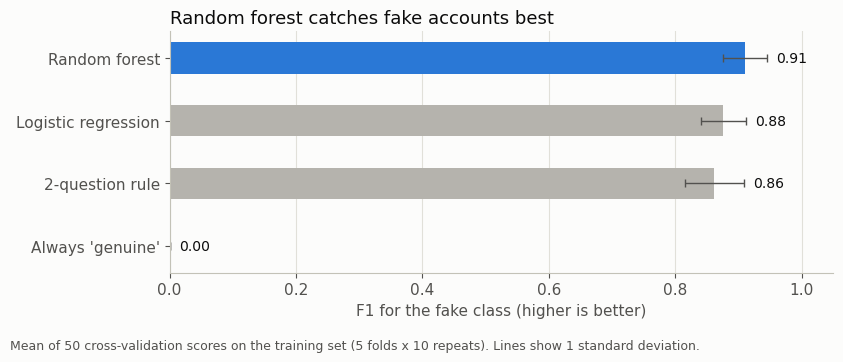

In [10]:
plot = cv_results.sort_values("F1")
colors = [BLUE if name == "Random forest" else GREY for name in plot.index]
fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.barh(plot.index, plot["F1"], height=0.5, color=colors)
ax.errorbar(plot["F1"], range(len(plot)), xerr=plot["F1 spread (std)"], fmt="none", ecolor=MUTED, elinewidth=1, capsize=3)
for i, (name, row) in enumerate(plot.iterrows()):
    ax.text(row["F1"] + row["F1 spread (std)"] + 0.015, i, f"{row['F1']:.2f}", va="center", color=INK, fontsize=10)
ax.set_xlim(0, 1.05)
ax.set_xlabel("F1 for the fake class (higher is better)")
ax.grid(axis="y", visible=False)
ax.set_title("Random forest catches fake accounts best", loc="left", fontsize=13)
fig.text(0.012, 0.01, "Mean of 50 cross-validation scores on the training set (5 folds x 10 repeats). Lines show 1 standard deviation.", color=MUTED, fontsize=9)
fig.tight_layout(rect=(0, 0.05, 1, 1))
fig.savefig("images/model_comparison.png", dpi=150)
plt.show()

- Always "genuine" scores F1 = 0: it never catches a fake, even though it is right about 83% of the time.
- The **2-question rule is already strong** (F1 0.862), so most of the signal is simple.
- **Random forest is the best** (precision 0.908, recall 0.915, F1 0.910, ROC-AUC 0.991). It had a higher F1 than the 2-question rule in 43 of the 50 folds, and than logistic regression in 39.

### What the 2-question rule learned

In [11]:
rule = DecisionTreeClassifier(max_depth=2, random_state=RANDOM_STATE).fit(X_train, y_train)
print(export_text(rule, feature_names=FEATURES))

|--- follower_following_ratio <= 0.16
|   |--- follower_following_ratio <= 0.09
|   |   |--- class: 1
|   |--- follower_following_ratio >  0.09
|   |   |--- class: 1
|--- follower_following_ratio >  0.16
|   |--- has_profile_pic <= 0.50
|   |   |--- class: 1
|   |--- has_profile_pic >  0.50
|   |   |--- class: 0



In words: **if an account has 0.16 followers or fewer for every account it follows (roughly 1 follower per 6 followed), call it fake. Otherwise, if it has no profile picture, call it fake. Otherwise, call it genuine.**

The tree also splits at 0.09 inside the first branch, but both sides answer "fake", so that split changes nothing.

## Step 7: The final test (done once)
The random forest had the best cross-validation F1, so it is the model I test. It is trained on the whole training set and scored on the 233 locked-away accounts. The 2-question rule is scored on the same accounts for comparison.

In [12]:
forest = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE).fit(X_train, y_train)
test_proba = forest.predict_proba(X_test)[:, 1]
test_pred = (test_proba >= 0.5).astype(int)
rule_pred = rule.predict(X_test)

def test_scores(pred, proba):
    return {"Precision": precision_score(y_test, pred), "Recall": recall_score(y_test, pred),
            "F1": f1_score(y_test, pred), "ROC-AUC": roc_auc_score(y_test, proba)}

test_results = pd.DataFrame({
    "Random forest": test_scores(test_pred, test_proba),
    "2-question rule": test_scores(rule_pred, rule.predict_proba(X_test)[:, 1]),
}).T
print(test_results.round(3))
print()
for name, pred in [("Random forest", test_pred), ("2-question rule", rule_pred)]:
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    print(f"{name}: caught {tp} of {tp + fn} fakes, wrongly flagged {fp} of {tn + fp} genuine accounts")
print()
print("Random forest macro F1 (average of the fake and genuine classes):", round(f1_score(y_test, test_pred, average="macro"), 3))

                 Precision  Recall     F1  ROC-AUC
Random forest        0.944    0.85  0.895    0.993
2-question rule      0.923    0.90  0.911    0.947

Random forest: caught 34 of 40 fakes, wrongly flagged 2 of 193 genuine accounts
2-question rule: caught 36 of 40 fakes, wrongly flagged 3 of 193 genuine accounts

Random forest macro F1 (average of the fake and genuine classes): 0.937


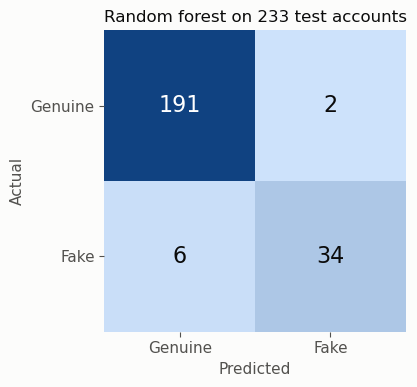

In [13]:
matrix = confusion_matrix(y_test, test_pred)
fig, ax = plt.subplots(figsize=(4.8, 4.0))
ax.imshow(matrix, cmap=plt.matplotlib.colors.LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#104281"]))
names = ["Genuine", "Fake"]
for i in range(2):
    for j in range(2):
        value = matrix[i, j]
        ax.text(j, i, str(value), ha="center", va="center", fontsize=16,
                color="white" if value > matrix.max() / 2 else INK)
ax.set_xticks([0, 1])
ax.set_xticklabels(names)
ax.set_yticks([0, 1])
ax.set_yticklabels(names)
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.grid(False)
for side in ["left", "bottom"]:
    ax.spines[side].set_visible(False)
ax.set_title(f"Random forest on {len(y_test)} test accounts", loc="left", fontsize=12)
fig.tight_layout()
fig.savefig("images/confusion_matrix.png", dpi=150)
plt.show()

On the 233 test accounts (40 fake), the random forest **caught 34 of the 40 fakes** (recall 0.850) and **wrongly flagged 2 of the 193 genuine accounts** (precision 0.944). F1 is 0.895 and ROC-AUC 0.993.

The 2-question rule caught 36 and wrongly flagged 3, a slightly higher F1 (0.911). But with only 40 fakes in the test set, one account moves recall by 2.5 points, so a 2-account gap is within noise. The 50-fold cross-validation is the more reliable comparison, and there the forest won 43 times out of 50.

Where the forest is clearly better is **ranking** (ROC-AUC 0.993 vs 0.947). It does not just say yes or no, it orders accounts from most to least suspicious, which is what you need to choose a cut-off (Step 10).

## Step 8: What does the forest look at?
**Permutation importance:** shuffle one column of the test set (so it carries no information), and measure how much ROC-AUC drops. A big drop means the model relies on that column.

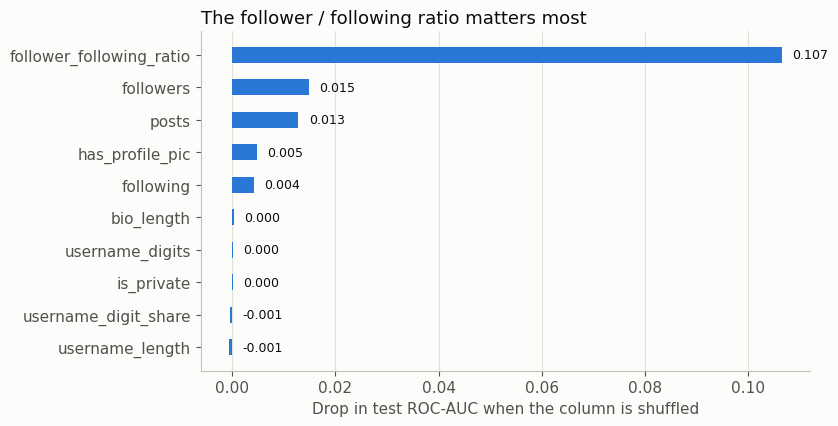

follower_following_ratio    0.1066
followers                   0.0149
posts                       0.0128
has_profile_pic             0.0048
following                   0.0042
bio_length                  0.0002
username_digits             0.0001
is_private                  0.0001
username_digit_share       -0.0005
username_length            -0.0007
dtype: float64

In [14]:
result = permutation_importance(forest, X_test, y_test, scoring="roc_auc", n_repeats=30, random_state=RANDOM_STATE)
importance = pd.Series(result.importances_mean, index=FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(8.5, 4.4))
ax.barh(importance.index, importance.values, height=0.5, color=BLUE)
for i, value in enumerate(importance.values):
    ax.text(max(value, 0) + 0.002, i, f"{value:.3f}", va="center", color=INK, fontsize=9)
ax.set_xlabel("Drop in test ROC-AUC when the column is shuffled")
ax.grid(axis="y", visible=False)
ax.set_title("The follower / following ratio matters most", loc="left", fontsize=13)
fig.tight_layout()
fig.savefig("images/feature_importance.png", dpi=150)
plt.show()
importance.sort_values(ascending=False).round(4)

The **follower / following ratio** matters by far the most: shuffling it lowers test ROC-AUC by about 0.11. Followers, posts, profile picture and following add a little. The username and privacy columns add almost nothing once the others are known.

One caution: followers and following look unimportant partly because the ratio already contains them. Shuffling one of them alone removes little information while the ratio is still intact. Permutation importance shows what *this model relies on*, not everything that is *related* to being fake.

## Step 9: Where does it go wrong?
Every test account the forest got wrong, with its fake probability:

In [15]:
mistakes = X_test.assign(actual=y_test.map({0: "genuine", 1: "fake"}), fake_probability=test_proba.round(2))
mistakes = mistakes[test_pred != y_test]
mistakes[["actual", "fake_probability", "posts", "followers", "following", "follower_following_ratio",
          "bio_length", "has_profile_pic", "is_private", "username_digits"]].sort_values("actual").round(2)

,actual,fake_probability,posts,followers,following,follower_following_ratio,bio_length,has_profile_pic,is_private,username_digits
178,fake,0.24,6,64,359,0.18,0,1,0,0
100,fake,0.25,2,643,2240,0.29,0,1,0,1
141,fake,0.36,0,29,41,0.71,0,0,1,0
99,fake,0.03,1,162,171,0.95,0,0,1,0
135,fake,0.05,3,71,31,2.29,57,1,0,1
19,fake,0.23,1,32,4,8.00,0,1,0,2
361,genuine,0.61,1,38,158,0.24,0,0,1,0
1075,genuine,0.53,6,70,808,0.09,0,1,0,1


- **The 6 missed fakes don't mass-follow.** Their follower / following ratios are 0.18 to 8.0, so the strongest signal is missing. Two of them are private with no profile picture and look like quiet genuine accounts.
- **The 2 genuine accounts flagged look fake on paper.** They have 1 and 6 posts and follow far more accounts than follow them (ratios 0.24 and 0.09). One has no profile picture. Their fake probabilities (0.61 and 0.53) are close to the 0.5 cut-off.

Profile numbers alone cannot separate these cases. Activity data, such as when and how often an account posts, likes and comments, would be needed.

## Step 10: Choosing the cut-off
The forest gives each account a fake probability, and 0.5 is only the default cut-off. To see the trade-off without touching the test set, I use cross-validated predictions on the training set: each account is scored by a forest that did not train on it.

In [16]:
oof_proba = cross_val_predict(RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE), X_train, y_train,
                              cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
                              method="predict_proba")[:, 1]
rows = []
for cutoff in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pred = (oof_proba >= cutoff).astype(int)
    rows.append({"Cut-off": cutoff, "Precision": precision_score(y_train, pred), "Recall": recall_score(y_train, pred),
                 "F1": f1_score(y_train, pred), "Accounts flagged": int(pred.sum())})
pd.DataFrame(rows).set_index("Cut-off").round(3)

,Precision,Recall,F1,Accounts flagged
Cut-off,,,,
0.3,0.850,0.956,0.900,180
0.4,0.888,0.938,0.912,169
0.5,0.912,0.912,0.912,160
0.6,0.934,0.888,0.910,152
0.7,0.956,0.819,0.882,137


- At the default **0.5**, precision and recall are both about 0.91.
- Lowering the cut-off to **0.3** catches 95.6% of the fakes, but 15% of the flagged accounts are then genuine (precision 0.850).
- Raising it to **0.7** makes flags more trustworthy (precision 0.956), but misses about 18% of the fakes (recall 0.819).

The right cut-off depends on what happens to a flagged account. If a person reviews every flag, a low cut-off is fine, because reviewers clear the false alarms. If flagged accounts are blocked automatically, a high cut-off protects genuine users. F1 is almost flat between 0.4 and 0.6, so 0.5 is a sensible default.

## Results

| Model | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|
| Always "genuine" (cross-validation) | 0.000 | 0.000 | 0.000 | 0.500 |
| 2-question rule (cross-validation) | 0.857 | 0.872 | 0.862 | 0.940 |
| Logistic regression (cross-validation) | 0.895 | 0.861 | 0.876 | 0.985 |
| Random forest (cross-validation) | 0.908 | 0.915 | 0.910 | 0.991 |
| **Random forest (test set, run once)** | **0.944** | **0.850** | **0.895** | **0.993** |

Precision, recall and F1 are for the fake class.

- Fake accounts follow many accounts and few follow them back. That ratio is the strongest signal.
- A 2-question rule gets most of the way. The random forest adds about 0.05 F1 in cross-validation and ranks accounts much better.
- On accounts it had never seen, the forest caught 34 of 40 fakes and wrongly flagged 2 of 193 genuine accounts.

**Context:** the paper that released this dataset reports macro-averaged F1 between 83.8% and 89.0% without oversampling (its Table VII), using 5 of these features and a 70/30 split. Macro F1 is the average of the fake and genuine classes, a different number from the fake-class F1 above. This forest's macro F1 on the test set is 0.937. The setups differ, so this is context, not a head-to-head comparison.

### Limitations
- **Small and old.** 200 fake accounts, collected in 2018. Fake accounts change their behaviour over time, so a real system would need fresh data and regular re-training.
- **Labels are human judgment.** The authors labelled suspicious accounts by hand, so the model learns *their* idea of fake.
- **Profile numbers only.** Fakes that look like ordinary private accounts cannot be separated with these features (see Step 9).

### Next steps
- Add activity features: posting times, likes and comments per post. The same repository has an automated-account dataset with these.
- Tune the forest (number of trees, tree depth) with cross-validation.
- Pick the cut-off together with the people who would act on the flags.